In [1]:
import numpy as np
import pandas as pd
import pickle
from scipy import signal
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.backends.backend_pdf import PdfPages
import os

In [2]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Dropout, Conv2D, BatchNormalization, Flatten
from tensorflow.keras.optimizers import SGD, RMSprop, Adam


from tensorflow.keras.layers import MaxPooling2D

I0000 00:00:1793602075.688747   46369 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793602075.713178   46369 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793602076.183012   46369 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [3]:
def bpf(e, fs, Wn, order):
    #fs = 2000
    #Wn = [0.1, 10]
    b, a = signal.iirfilter(order, Wn, btype = 'bandpass',
                        analog = False, ftype='butter', fs = fs)
    w, h = signal.freqz(b, a, fs=fs)

#    fig, ax = plt.subplots()
#    plt.grid(which="both")
#    ax.plot(w, 20*np.log(abs(h)))
#    ax.axis((0, 100, -100, 10))
#    ax.set_ylabel('Amplitude [dB]')
#    ax.set_xlabel('Freq [Hz]')

    return signal.filtfilt(b, a, e)

In [4]:
def notchf(e, fs, w0, Q):
    b, a = signal.iirnotch(w0, Q, fs)
    return signal.filtfilt(b, a, e)

In [5]:
class EEG_data:
    def __init__(self, label, time, eeg):
        self.time = time
        self.eeg = eeg
        self.label = label

In [6]:
from keras import models

In [7]:

my_model=models.load_model('model/model_pt1.keras')
my_model.load_weights('model/model_weight_pt1.weights.h5')

W0000 00:00:1793602100.111278   46369 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [8]:
from tensorflow.keras.models import load_model
from tensorflow.keras import models
import tensorflow as tf

In [9]:
cm = plt.get_cmap('jet')

In [10]:
from keras.models import Model

In [11]:
my_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)           │ (None, 61, 41, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 61, 41, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv3 (Conv2D)           │ (None, 61, 41, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 30, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 30, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 30, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv3 (Conv2D)           │ (None, 30, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 10, 10, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 10, 10, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 10, 10, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 128)            │       819,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,239,493 (31.43 MB)

 Trainable params: 2,746,497 (10.48 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,492,996 (20.95 MB)

## validate w/ data on day 9

In [12]:
list_evolving_v = pd.read_pickle('data/hyp_evolving_pt1_day9.pickle')
list_aborted_v = pd.read_pickle('data/hyp_aborted_pt1_day9.pickle')

hyp_evolving_pt1_day9


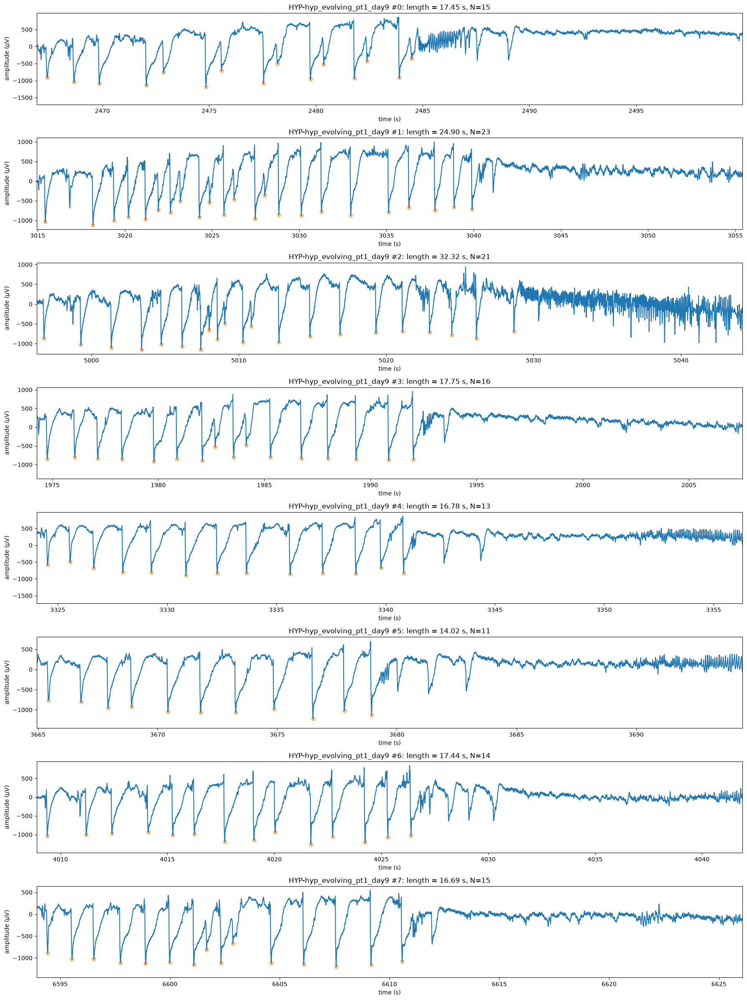

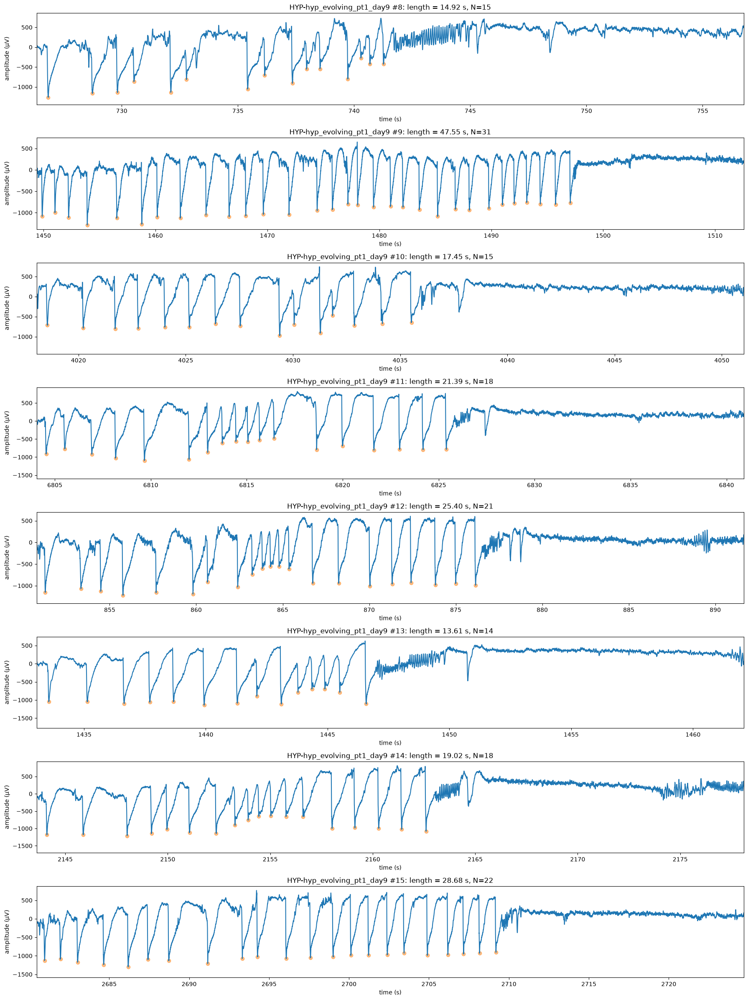

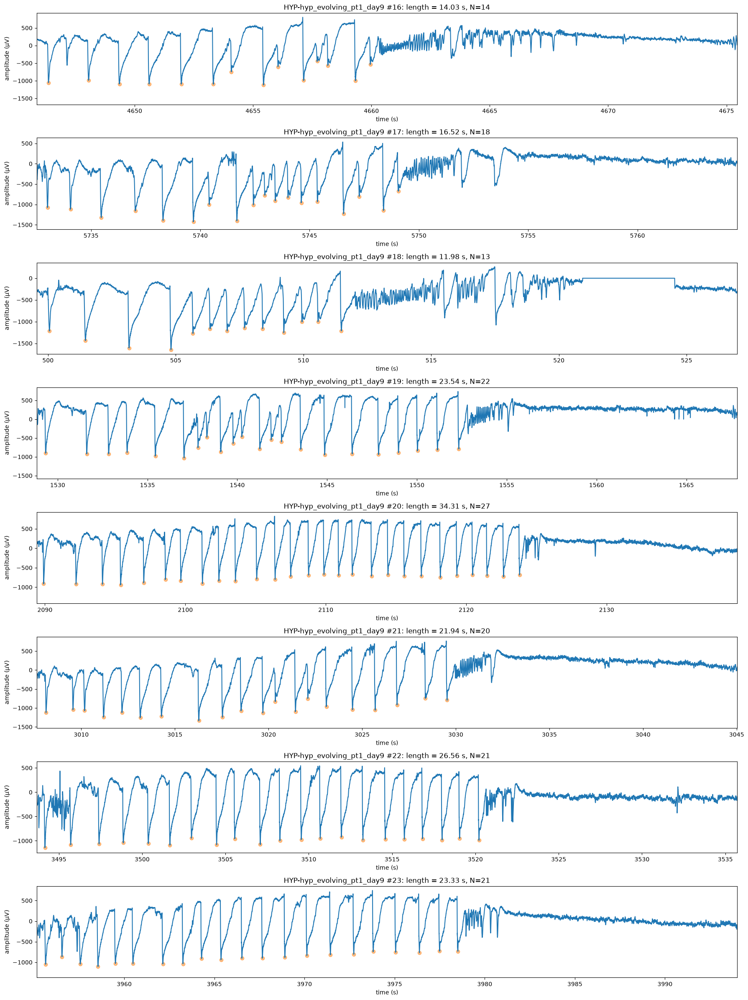

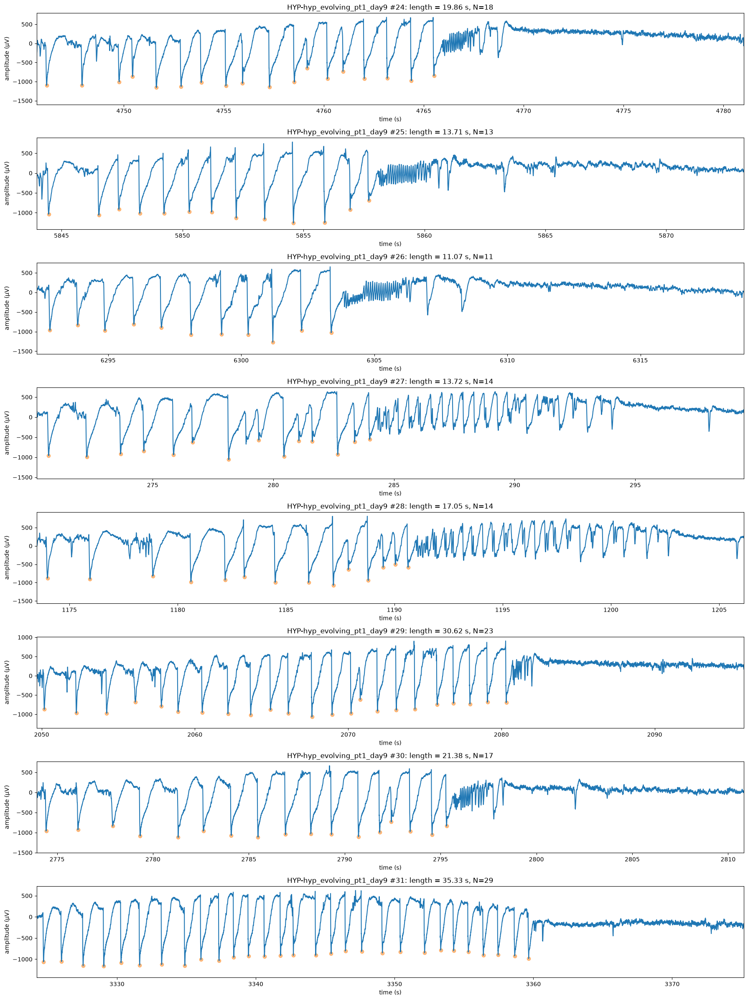

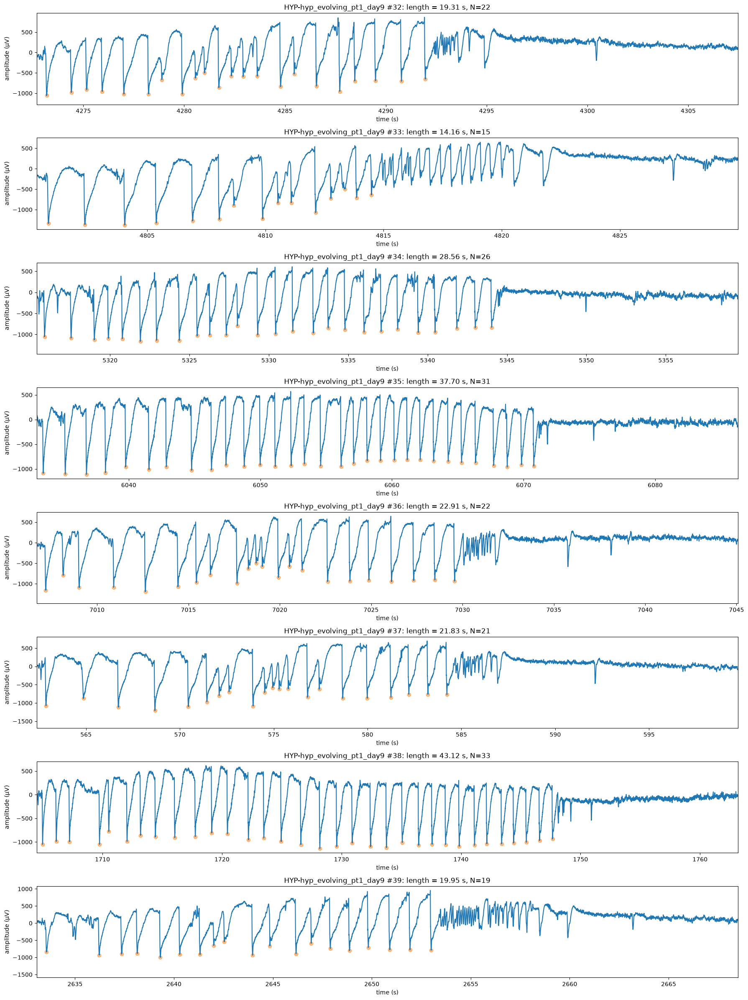

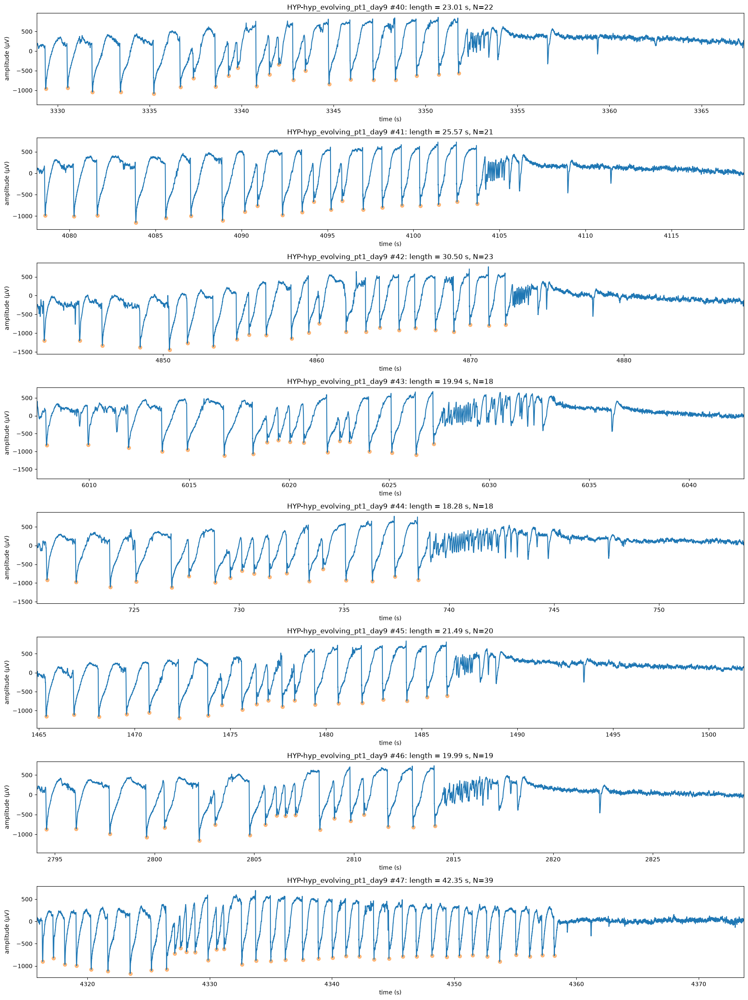

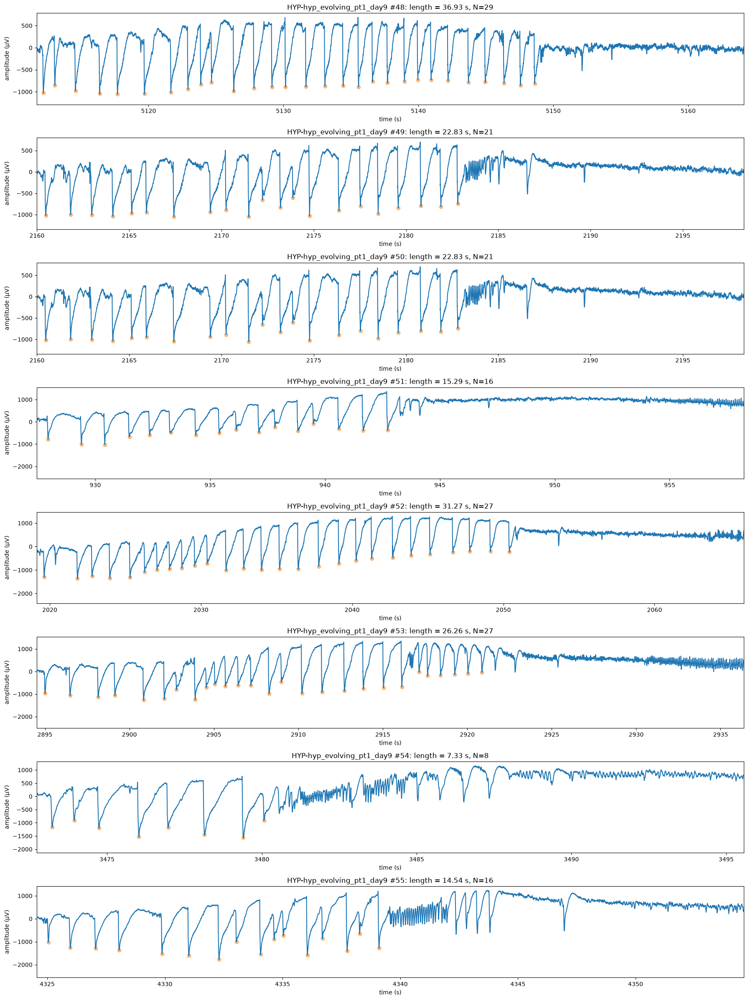

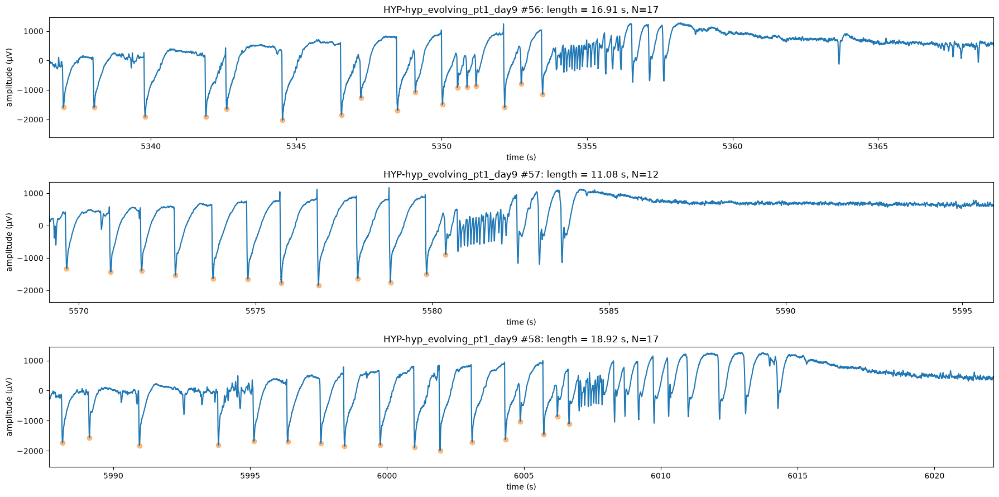

hyp_aborted_pt1_day9


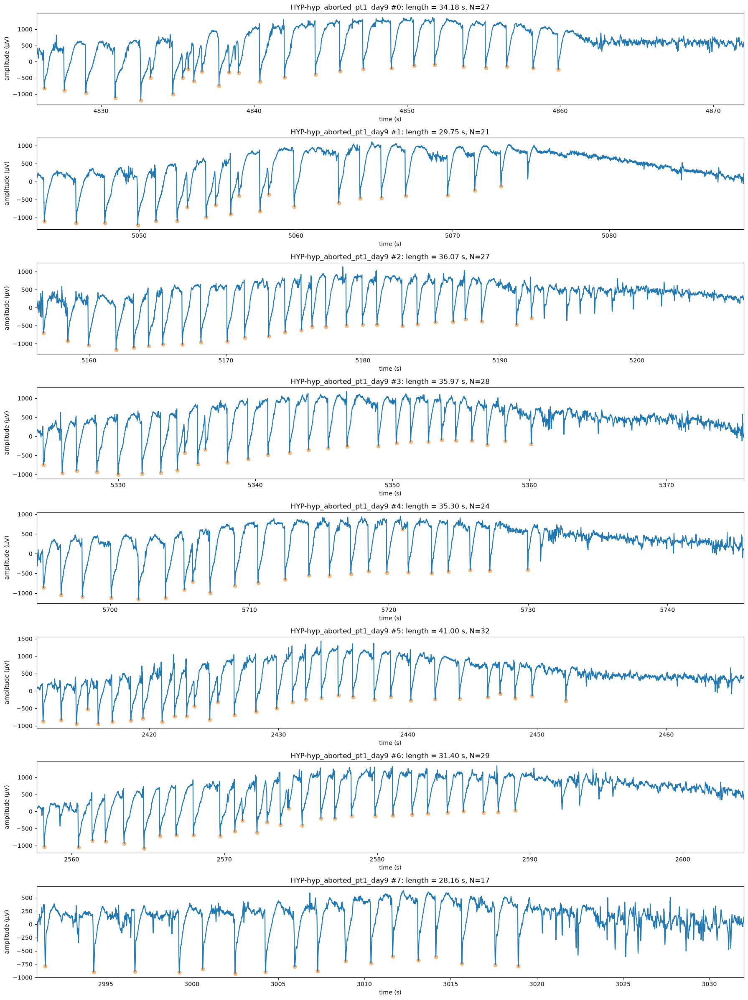

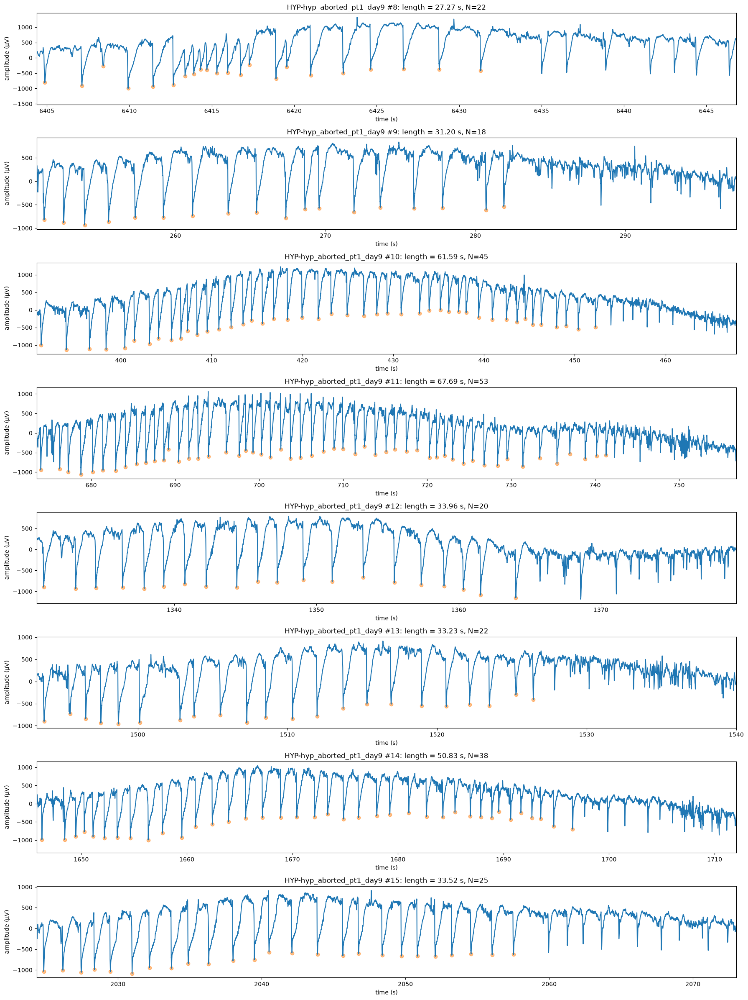

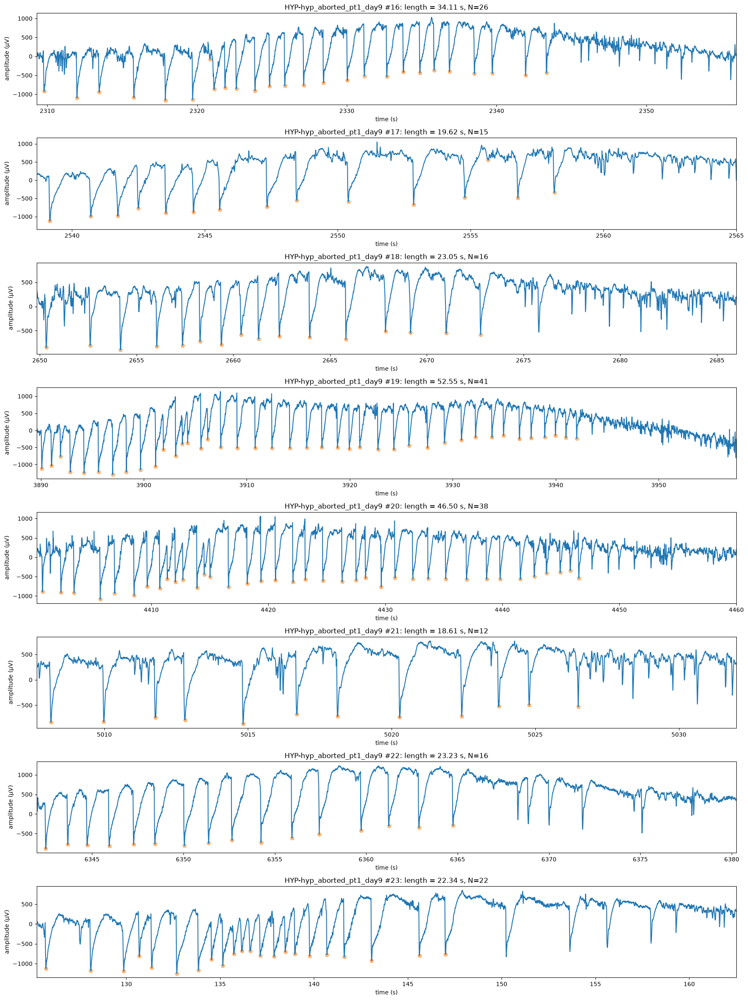

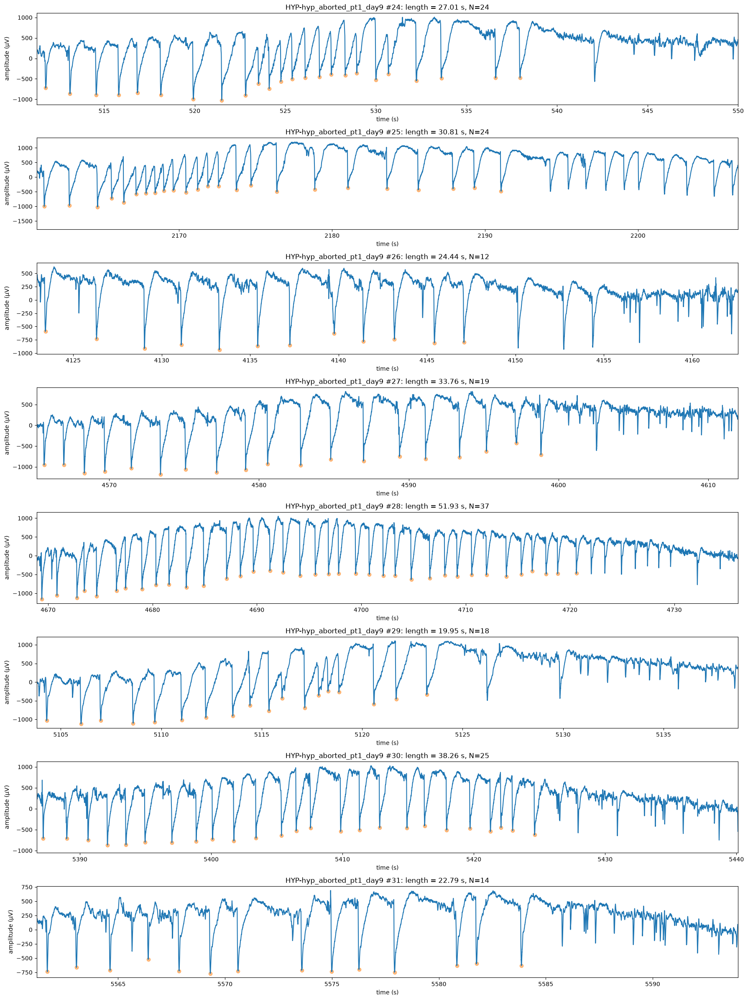

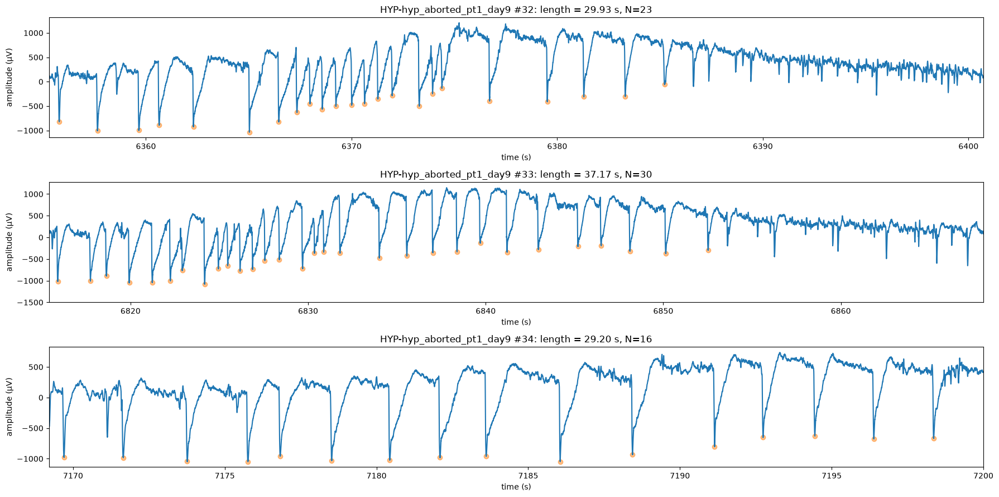

In [13]:
# show hyp and save to pdf

dict_list_hyp = {'hyp_evolving_pt1_day9':list_evolving_v, 'hyp_aborted_pt1_day9':list_aborted_v}

os.makedirs('./pdf', exist_ok=True)

for k, v in dict_list_hyp.items():
    print(k)

    with PdfPages(os.path.join('pdf', k+'_plots.pdf')) as pdf:

        len_eeg = len(v)
        plots_per_page = 8

        for i, l in enumerate(v):
            n_ax = i%plots_per_page
            if n_ax==0:
                n_page = (i//plots_per_page)+1
                rest_ax = min(n_page*plots_per_page, len_eeg)-i
                fig, ax = plt.subplots(rest_ax, 1, figsize=(18, 3*rest_ax), squeeze=False)

            ax[n_ax, 0].plot(l.time, l.eeg)
            ax[n_ax, 0].set_title('HYP-'+k+' #{}: length = {:.2f} s, N={}'.format(i, l.np_data[-1, 1]-l.np_data[0, 0], l.np_data.shape[0]))
            ax[n_ax, 0].set_xlabel('time (s)')
            ax[n_ax, 0].set_ylabel('amplitude (\u03bcV)')
            for ind in range(l.np_data.shape[0]):
                ax[n_ax, 0].scatter(l.np_data[ind, 4], l.np_data[ind, 5], color='tab:orange', alpha=0.5)
            ax[n_ax, 0].set_xlim((l.np_data[0, 4]-0.5, min(l.np_data[-1, 4]+0.5+15, l.time[-1])))
            if n_ax==(rest_ax-1):
                plt.tight_layout()
                pdf.savefig()
                plt.show()

In [14]:
# preprocess function

def preproc_spectro(e):
    temp = e.copy()
    f_list, t_list, temp = signal.spectrogram(temp, fs, nperseg=nperseg, noverlap=noverlap) # change to spectrogram
    temp = temp[:61, :] # target frequency is 0-600 Hz
    temp = 20*np.log10(np.abs(temp)) #spectrogram to dB
    temp = temp-np.median(temp[:, 0:8], axis = 1).reshape(-1, 1) #baseline adjustment(median of left 20%)
    temp = (temp-temp.min())/(temp.max()-temp.min()) #normalize to 0-1
    return temp, f_list, t_list

In [15]:
# データの入れものを作っておく
list_redspectro = []
list_redlabel = []
list_greenspectro = []
list_greenlabel = []

# 設定
fs = 2000 #周波数
nperseg = 200
noverlap = 175
backstep = 600
forwardstep = 600

for i, l in enumerate(list_evolving_v):
    EEG = l.eeg
    t_0 = l.np_data[0, 4]
    t_last = l.np_data[-1, 4]
    t_width = (t_last-t_0)/5

    for k in range(l.np_data.shape[0]):
        t_ind=int(np.where(l.time==l.np_data[k, 4])[0].item()) #get index of peaks
        if t_ind>=backstep:
            if (l.np_data[k, 4]>=t_0+2*t_width)&(l.np_data[k, 4]<=t_0+5*t_width):# if in segment 3-5
                temp = l.eeg[t_ind-backstep:t_ind+forwardstep+1].copy() #crop -0.3 to +0.3 data from t_peak
                temp, _, _ = preproc_spectro(temp)
                list_redspectro.append(temp)
                list_redlabel.append([i, k]) #store where the data is from (i: index of EEG_list, k: index of discharge)
            elif l.np_data[k, 4]<=(t_0+t_width):
                temp = l.eeg[t_ind-backstep:t_ind+forwardstep+1].copy() #crop -0.3 to +0.3 data from t_peak
                temp, _, _ = preproc_spectro(temp)
                list_greenspectro.append(temp)
                list_greenlabel.append([i, k]) #store where the data is from (i: index of EEG_list, k: index of discharge)
        else:
            print('warning: EEG#{} discharge#{} does not have enough backward margin.'.format(i, k))

for i, l in enumerate(list_aborted_v):
    t_0 = l.np_data[0, 4]
    t_last = l.np_data[-1, 4]
    t_width = (t_last-t_0)/5

    for k in range(l.np_data.shape[0]):
        t_ind=int(np.where(l.time==l.np_data[k, 4])[0].item())
        if t_ind>=backstep:
            temp = l.eeg[t_ind-backstep:t_ind+forwardstep+1].copy()
            temp, f_list, t_list = preproc_spectro(temp)
            list_greenspectro.append(temp)
            list_greenlabel.append([i, k])
        else:
            print('warning: EEG#{} discharge#{} does not have enough backward margin.'.format(i, k))
f_list = f_list[np.where(f_list<=600)]

In [16]:
allspectro_v = np.array(list_redspectro+list_greenspectro)
X_test = np.reshape(allspectro_v, (-1, 61, 41, 1))
y_test = np.concatenate([np.repeat(1, len(list_redspectro)), np.repeat(0, len(list_greenspectro))]).reshape(-1, 1)

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, f1_score, roc_curve, roc_auc_score

In [19]:
y_pred = my_model.predict(X_test)
y_pred_bool = (y_pred>=0.5)

dict_score = {}
for key, f in zip(['accuracy', 'precision', 'recall'], [accuracy_score, precision_score, recall_score]):
    dict_score[key] = f(y_test, y_pred_bool)
dict_score['f1'] = f1_score(y_test, y_pred_bool, average='binary')
dict_score['roc_auc'] = roc_auc_score(y_test, y_pred)

cm = confusion_matrix(y_test, y_pred_bool)


58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step


In [20]:
print(dict_score)

{'accuracy': 0.8170865279299014, 'precision': 0.7369640787949016, 'recall': 0.8559892328398385, 'f1': 0.7920298879202988, 'roc_auc': 0.8971117316561221}


In [21]:
print(cm)

[[856 227]
 [107 636]]


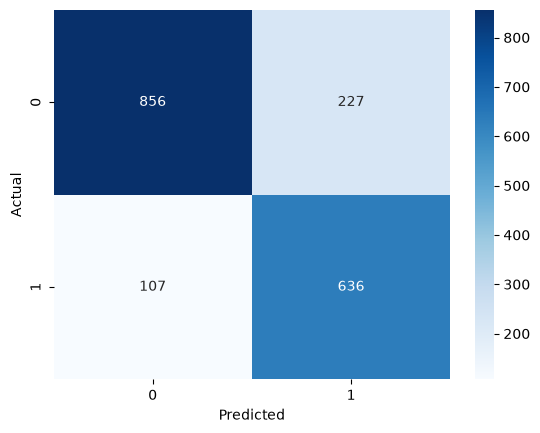

In [22]:
import seaborn as sns

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [23]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred)

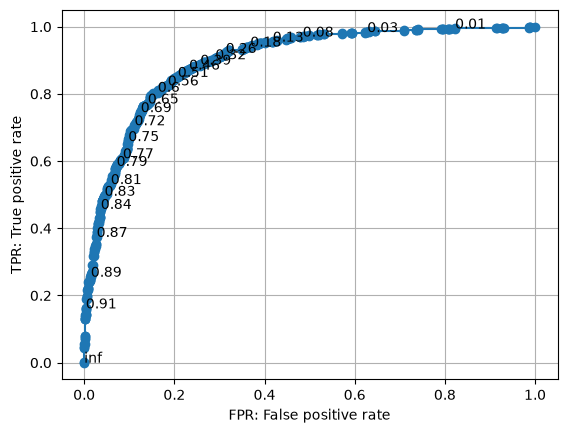

In [24]:
plt.plot(fpr, tpr, marker='o')
for x, y, t in zip(fpr[::20], tpr[::20], thresholds[::20]):
    plt.annotate(xy=(x, y), text=str(round(t, 2)))
plt.xlabel('FPR: False positive rate')
plt.ylabel('TPR: True positive rate')
plt.grid()